# 01 | CPI Data Audit and Index Reconstruction

## Purpose

This notebook establishes that the monthly mainland China CPI data are suitable for the forecasting analysis that follows. It performs four tasks:

1. load the four published CPI inflation series through the project's validated data loader;
2. document their dates, frequency, types, and periods of availability;
3. reconstruct headline and core CPI index paths from the published month-on-month rates;
4. compare year-on-year inflation implied by those reconstructed paths with the published year-on-year series.

The reconstruction is a **data-integrity check and a forecasting transformation**, not an attempt to replace the official published series. Subsequent notebooks model published month-on-month inflation. Multi-step monthly forecasts are compounded into index paths and then converted to year-on-year inflation for evaluation, so the conversion implemented here must behave coherently before model development begins.

> **Data access:** The CPI extract is obtained from CEIC Data through the SMU Libraries subscription. The licensed raw file is kept locally and must not be committed to the public repository. The repository should contain only access instructions, a data dictionary, code, and derived outputs that do not reproduce the licensed source dataset.

## 1. Reproducible setup

The notebook is designed to run from the repository's `notebooks/` directory. `PROJECT_ROOT` therefore points to the parent directory, which allows all project files to be addressed through relative paths. The two imported project functions centralise schema validation and the reconstruction logic in `src/` rather than duplicating those rules inside the notebook.

In [19]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
if not (PROJECT_ROOT / "src").exists():
    raise RuntimeError(
        "Run this notebook from the repository's notebooks/ directory."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.features.reconstruct_index import add_reconstructed_indices

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "china_cpi.csv"

print("Working directory: notebooks/")
print("Project root: repository root")
print("Python environment: project virtual environment")
print("Licensed data file found:", DATA_PATH.exists())

Working directory: notebooks/
Project root: repository root
Python environment: project virtual environment
Licensed data file found: True


## 2. Load and validate the published series

`load_cpi_series()` is responsible for translating the local CEIC extract into a standard monthly `DataFrame`. The expected output has a month-start `DatetimeIndex` named `date` and four numeric columns:

- `headline_yoy_published`: published headline year-on-year inflation, percentage points;
- `headline_mom_published`: published headline month-on-month inflation, percentage points;
- `core_yoy_published`: published core year-on-year inflation, percentage points;
- `core_mom_published`: published core month-on-month inflation, percentage points.

Different series begin at different dates. Missing values before a series begins are expected and should not be imputed.

In [20]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "The licensed CEIC extract is not available at the documented local path. "
        "Follow the README access instructions and keep the file outside version control."
    )

cpi = load_cpi_series(DATA_PATH)

expected_columns = [
    "headline_yoy_published",
    "headline_mom_published",
    "core_yoy_published",
    "core_mom_published",
]

assert isinstance(cpi, pd.DataFrame)
assert cpi.index.name == "date"
assert isinstance(cpi.index, pd.DatetimeIndex)
assert cpi.index.is_monotonic_increasing
assert cpi.index.is_unique
assert cpi.columns.tolist() == expected_columns
assert all(dtype == "float64" for dtype in cpi.dtypes.astype(str))

print("Data shape:", cpi.shape)
print("Index range:", cpi.index.min().date(), "to", cpi.index.max().date())
print("Index frequency:", cpi.index.freqstr or pd.infer_freq(cpi.index))

display(cpi.head())
display(cpi.tail())

Data shape: (500, 4)
Index range: 1985-01-01 to 2026-08-01
Index frequency: MS


,headline_yoy_published,headline_mom_published,core_yoy_published,core_mom_published
date,,,,
1985-01-01,5.5,NaN,NaN,NaN
1985-02-01,6.5,NaN,NaN,NaN
1985-03-01,7.0,NaN,NaN,NaN
1985-04-01,7.8,NaN,NaN,NaN
1985-05-01,9.9,NaN,NaN,NaN


,headline_yoy_published,headline_mom_published,core_yoy_published,core_mom_published
date,,,,
2026-04-01,1.2,0.3,1.2,0.2
2026-05-01,1.2,-0.1,1.1,-0.1
2026-06-01,1.0,-0.3,1.0,-0.1
2026-07-01,0.5,-0.1,0.9,0.3
2026-08-01,0.8,0.4,1.0,0.1


### Series availability

The following summary distinguishes the full monthly index from the usable span of each series. This matters because the project's common headline-and-core modelling sample must begin only when both published month-on-month series are available.

In [21]:
availability_rows = []

for column in cpi.columns:
    observed = cpi[column].dropna()
    availability_rows.append(
        {
            "series": column,
            "non_null_observations": observed.size,
            "first_observation": observed.index.min(),
            "last_observation": observed.index.max(),
            "dtype": str(cpi[column].dtype),
        }
    )

availability = (
    pd.DataFrame(availability_rows)
    .set_index("series")
)

display(availability)

common_mom = cpi[
    ["headline_mom_published", "core_mom_published"]
].dropna()

print(
    "Common headline-and-core MoM sample:",
    common_mom.index.min().date(),
    "to",
    common_mom.index.max().date(),
)
print("Common MoM observations:", len(common_mom))

,non_null_observations,first_observation,last_observation,dtype
series,,,,
headline_yoy_published,500,1985-01-01,2026-08-01,float64
headline_mom_published,380,1995-01-01,2026-08-01,float64
core_yoy_published,248,2006-01-01,2026-08-01,float64
core_mom_published,248,2006-01-01,2026-08-01,float64


Common headline-and-core MoM sample: 2006-01-01 to 2026-08-01
Common MoM observations: 248


## 3. Reconstruct CPI index paths from month-on-month inflation

For a published month-on-month inflation rate $m_t$, expressed in percentage points, the reconstructed index evolves according to

$$
P_t = P_{t-1}\left(1 + \frac{m_t}{100}\right).
$$

Because only relative movements matter, the starting level is an arbitrary base value chosen by the project function. The implied year-on-year inflation rate is then

$$
\pi_t^{\mathrm{YoY}}
=
100\left(\frac{P_t}{P_{t-12}} - 1\right).
$$

The same transformation is applied separately to headline and core inflation. The resulting index paths later allow a sequence of monthly forecasts to be compounded consistently across forecast horizons.

In [22]:
cpi_reconstructed = add_reconstructed_indices(cpi)

expected_reconstructed_columns = expected_columns + [
    "headline_index_reconstructed",
    "core_index_reconstructed",
    "headline_yoy_reconstructed",
    "core_yoy_reconstructed",
    "headline_yoy_discrepancy",
    "core_yoy_discrepancy",
]

assert cpi_reconstructed.index.equals(cpi.index)
assert cpi_reconstructed.columns.tolist() == expected_reconstructed_columns

print("Reconstructed data shape:", cpi_reconstructed.shape)
display(cpi_reconstructed.tail())

Reconstructed data shape: (500, 10)


,headline_yoy_published,headline_mom_published,core_yoy_published,core_mom_published,headline_index_reconstructed,core_index_reconstructed,headline_yoy_reconstructed,core_yoy_reconstructed,headline_yoy_discrepancy,core_yoy_discrepancy
date,,,,,,,,,,
2026-04-01,1.2,0.3,1.2,0.2,177.527703,124.787561,1.298736,1.200351,0.098736,0.000351
2026-05-01,1.2,-0.1,1.1,-0.1,177.350175,124.662774,1.400238,1.099150,0.200238,-0.000850
2026-06-01,1.0,-0.3,1.0,-0.1,176.818125,124.538111,1.197235,0.998051,0.197235,-0.001949
2026-07-01,0.5,-0.1,0.9,0.3,176.641307,124.911725,0.693264,0.897456,0.193264,-0.002544
2026-08-01,0.8,0.4,1.0,0.1,177.347872,125.036637,1.096037,0.998353,0.296037,-0.001647


### How to interpret the discrepancy columns

For each target, the notebook defines

$$
\mathrm{discrepancy}_t
=
\mathrm{reconstructed\ YoY}_t
-
\mathrm{published\ YoY}_t.
$$

A discrepancy is therefore not automatically a data error. Published month-on-month rates are rounded, while the official year-on-year series may be calculated from higher-precision index levels. Compounding rounded monthly rates can accumulate small differences, especially over a 12-month window. The audit asks whether those differences are modest and explainable rather than whether every reconstructed value exactly equals the official release.

In [23]:
AUDIT_START = pd.Timestamp("2006-01-01")

discrepancy_columns = [
    "headline_yoy_discrepancy",
    "core_yoy_discrepancy",
]

discrepancy_audit = cpi_reconstructed.loc[
    AUDIT_START:,
    discrepancy_columns,
]

discrepancy_summary = discrepancy_audit.describe().T

discrepancy_summary["mean_absolute"] = (
    discrepancy_audit.abs().mean()
)
discrepancy_summary["max_absolute"] = (
    discrepancy_audit.abs().max()
)

display(discrepancy_summary)

latest_comparison_columns = [
    "headline_yoy_published",
    "headline_yoy_reconstructed",
    "headline_yoy_discrepancy",
    "core_yoy_published",
    "core_yoy_reconstructed",
    "core_yoy_discrepancy",
]

display(
    cpi_reconstructed[latest_comparison_columns].tail(12)
)

,count,mean,std,min,25%,50%,75%,max,mean_absolute,max_absolute
headline_yoy_discrepancy,248.0,0.005544,0.131437,-0.313920,-0.091581,0.002290,0.093527,0.592205,0.099050,0.592205
core_yoy_discrepancy,236.0,-0.033146,0.117175,-0.305097,-0.100232,-0.001798,0.012397,0.299598,0.095228,0.305097


,headline_yoy_published,headline_yoy_reconstructed,headline_yoy_discrepancy,core_yoy_published,core_yoy_reconstructed,core_yoy_discrepancy
date,,,,,,
2025-09-01,-0.3,-0.505565,-0.205565,1.0,1.002296,0.002296
2025-10-01,0.2,-0.006596,-0.206596,1.2,1.204301,0.004301
2025-11-01,0.7,0.496389,-0.203611,1.2,1.204301,0.004301
2025-12-01,0.8,0.697382,-0.102618,1.2,1.204301,0.004301
2026-01-01,0.2,0.197395,-0.002605,0.8,1.002899,0.202899
2026-02-01,1.3,1.402173,0.102173,1.8,1.913747,0.113747
2026-03-01,1.0,1.096745,0.096745,1.1,1.200351,0.100351
2026-04-01,1.2,1.298736,0.098736,1.2,1.200351,0.000351
2026-05-01,1.2,1.400238,0.200238,1.1,1.099150,-0.000850


### Audit interpretation

The reconstructed series should track the published year-on-year series closely in timing and direction. Small non-zero discrepancies are expected because the published month-on-month inputs are rounded before being compounded. The summary above should be read using three checks:

1. the mean discrepancy should be small relative to the scale of inflation;
2. the mean absolute discrepancy should remain modest;
3. isolated larger differences should not coincide with missing observations, index breaks, or impossible reconstructed values.

The core reconstruction is typically especially close to the published series. Headline discrepancies can be somewhat larger because rounded monthly food and energy movements compound over the year. These differences justify evaluating model forecasts against the official published year-on-year series rather than treating the reconstructed values as the official target.

## 4. Visual comparison of published and reconstructed inflation

The plots provide the most direct audit of timing, turning points, and magnitude. Close overlap indicates that the compounding function preserves the economic path of both headline and core inflation. Visible gaps represent the rounding-related discrepancies quantified above.

Saved: outputs/figures/01_cpi_reconstruction_audit.png


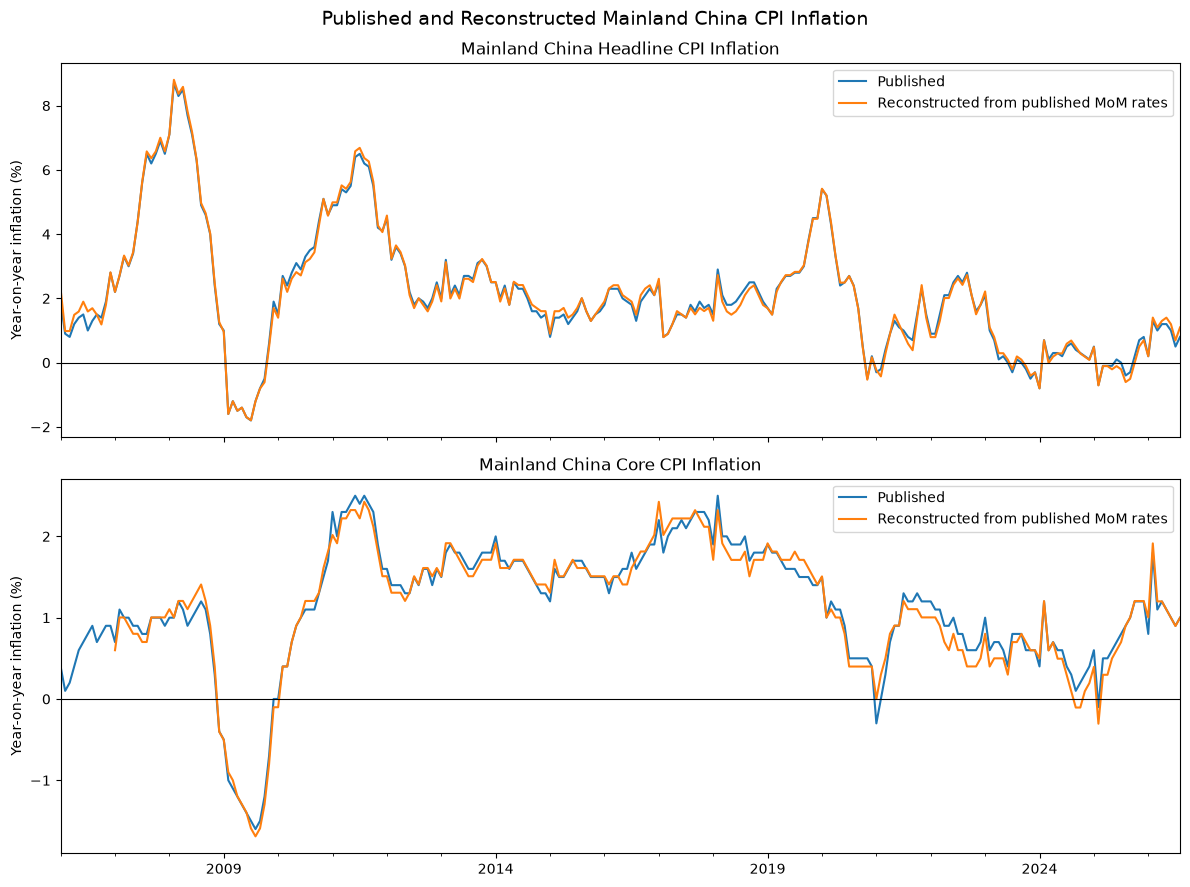

In [24]:
# Complete runnable example: compare and export reconstructed CPI inflation

plot_start = pd.Timestamp("2006-01-01")

plot_specs = [
    (
        "headline_yoy_published",
        "headline_yoy_reconstructed",
        "Mainland China Headline CPI Inflation",
    ),
    (
        "core_yoy_published",
        "core_yoy_reconstructed",
        "Mainland China Core CPI Inflation",
    ),
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 9),
    sharex=True,
)

for axis, (published, reconstructed, title) in zip(axes, plot_specs):
    comparison = cpi_reconstructed.loc[
        plot_start:,
        [published, reconstructed],
    ].rename(
        columns={
            published: "Published",
            reconstructed: "Reconstructed from published MoM rates",
        }
    )

    comparison.plot(ax=axis)
    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel("Year-on-year inflation (%)")
    axis.axhline(0, color="black", linewidth=0.8)

fig.suptitle(
    "Published and Reconstructed Mainland China CPI Inflation",
    fontsize=14,
)
fig.tight_layout()

OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures"
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

figure_path = (
    OUTPUT_FIGURES
    / "01_cpi_reconstruction_audit.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    "Saved:",
    figure_path.relative_to(PROJECT_ROOT),
)

plt.show()


## 5. Data-audit conclusion

This notebook establishes the input and transformation rules used by the rest of the project:

- the loader produces a unique, ordered monthly index and the four expected numeric series;
- the series have different historical start dates, so later notebooks must declare their modelling samples explicitly;
- headline and core month-on-month rates can be compounded into coherent reconstructed index paths;
- year-on-year inflation implied by those paths broadly tracks the official published series;
- residual differences are retained and reported because rounded monthly releases do not reproduce all official year-on-year values exactly.

The project therefore treats **published month-on-month inflation** as the modelling input and **published year-on-year inflation** as the final evaluation target after forecast paths are compounded. The reconstructed indices are intermediate analytical objects, not substitutes for official CPI levels.

### Dependency for the next notebooks

`cpi_reconstructed` provides the validated data object required for exploratory analysis and the later forecast-transformation checks. Model-development notebooks should load data afresh through the project functions rather than relying on this notebook's in-memory state.

In [25]:
# Complete runnable example: export aggregated data-audit table

OUTPUT_TABLES = PROJECT_ROOT / "outputs" / "tables"
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

discrepancy_export = (
    discrepancy_summary.reset_index()
    .rename(columns={"index": "series"})
)

discrepancy_output_path = (
    OUTPUT_TABLES
    / "01_reconstruction_discrepancy_summary.csv"
)

discrepancy_export.to_csv(
    discrepancy_output_path,
    index=False,
)

print(
    "Saved:",
    discrepancy_output_path.relative_to(PROJECT_ROOT),
)


Saved: outputs/tables/01_reconstruction_discrepancy_summary.csv
